# CS 430 – Assignment 2: SLCM Regression Analysis



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 1 – Get to Know the Prediction Problem

### 1. Load the dataset and examine its structure.

- Load the CSV file into pandas.
- Display the first 5 rows.
- Report the number of rows and columns.
- Print the column names.
- Use `info()` to inspect the dataset.

**Answer:**
- Which variable will be the target?
- Which columns appear to be numerical?
- Which columns appear to be categorical?


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/SLCM_rent_arrears_student_clean.csv")

display(df.head())

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset info:")
df.info()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


Rows: 1754
Columns: 14

Column names:
['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_vouche

The target variable for this model is past_due_rent because that is what I am trying to predict. The numerical columns are adults_in_household, children_in_household, monthly_household_income, monthly_rent, and past_due_rent. The categorical columns are household_has_65plus, income_sources, employment_status, has_housing_voucher, eviction_in_progress, behind_on_utilities, main_reason_behind_on_rent, and intake_quarter. record_id is stored as an object, but it is really just an identifier and should not be used as a feature.


### 2. Investigate missing values.

- Calculate the number of missing values in every column.
- Identify which variables contain missing data.
- Briefly describe how you plan to handle those missing values before modeling.

Do not simply remove all rows with missing data unless you can justify that decision.


In [ ]:
missing_values = df.isna().sum()
print(missing_values)

print("\nColumns with missing data:")
print(missing_values[missing_values > 0])

record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64

Columns with missing data:
monthly_household_income      108
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
monthly_rent                    8
dtype: int64


There are missing values in five columns. monthly_household_income has 108 missing values, eviction_in_progress has 1, behind_on_utilities has 7, main_reason_behind_on_rent has 16, and monthly_rent has 8. I would not remove all of these rows because that would get rid of useful data, especially since most of the dataset is still complete. For the numerical columns like income and rent, I would fill in the missing values using the median. For the categorical columns, I would fill in the missing values using the most common category before training the models.

### 3. Explore the target variable: past_due_rent.

Calculate:
- count
- mean
- median
- standard deviation
- minimum
- maximum

Create:
- a histogram
- a boxplot

**Answer:**
- What does the distribution look like?
- Is the distribution symmetric or skewed?
- Are the mean and median similar?
- Do you notice any unusually high values?
- Why might rent-arrears data naturally contain a wide range of values?

Do not automatically remove an observation simply because it is high.


In [ ]:
target = df["past_due_rent"]

print("Count:", target.count())
print("Mean:", target.mean())
print("Median:", target.median())
print("Standard deviation:", target.std())
print("Minimum:", target.min())
print("Maximum:", target.max())

Count: 1754
Mean: 2408.0069327251995
Median: 2000.0
Standard deviation: 2089.5153715749434
Minimum: 0.0
Maximum: 20000.0


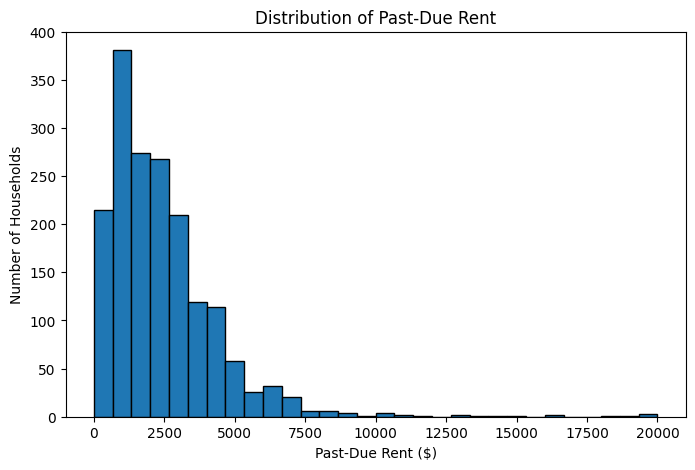

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df["past_due_rent"], bins=30, edgecolor="black")
plt.xlabel("Past-Due Rent ($)")
plt.ylabel("Number of Households")
plt.title("Distribution of Past-Due Rent")
plt.show()


The distribution is right skewed. Most households owe a few thousand dollars or less, while a smaller number owe much larger amounts. The mean is higher than the median, which also points to a right skewed distribution.


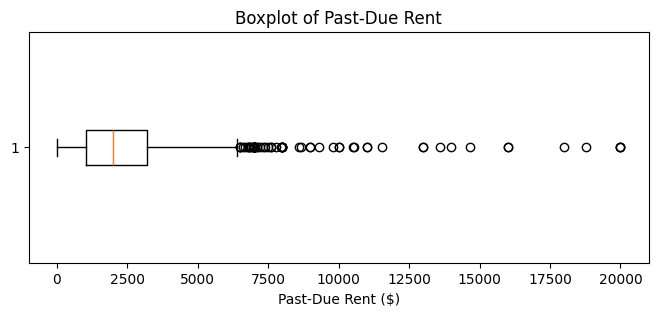

In [ ]:
plt.figure(figsize=(8, 3))
plt.boxplot(df["past_due_rent"], vert=False)
plt.xlabel("Past-Due Rent ($)")
plt.title("Boxplot of Past-Due Rent")
plt.show()

There are several unusually high past due rent values, including values reaching $20,000. I would not automatically remove them because they could represent real households that have been behind on rent for a long time, have higher monthly rent, or experienced a serious loss of income. Rent arrears can naturally have a wide range because every household has a different rent amount, financial situation, and length of time that they have been behind.


## Part 2 – Prepare the Data for Machine Learning

### 4. Create your input features and target.

Create X and y using past_due_rent as the target. Do not use record_id as an input feature.

**Answer:**  
Why should `record_id` not be used to predict past-due rent?


In [ ]:
X = df.drop(columns=["past_due_rent", "record_id"])
y = df["past_due_rent"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1754, 12)
y shape: (1754,)


record_id should not be used because it is just a label used to uniquely identify each record. It does not describe anything meaningful about the household's finances, employment, or housing situation.  


### 5. Separate the numerical and categorical features.

- Create lists containing numerical features and categorical features.
- Display both lists.
- Briefly explain why machine-learning models require different preparation steps for numerical and categorical variables.


In [ ]:
# select d types based on if they contain a number or not
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']

Categorical features:
['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


Numerical and categorical variables need different preparation because they contain different types of information. Numerical variables already contain numbers that can be scaled and used in calculations. Categorical variables contain text labels, so they have to be converted into a numerical representation before a regression model can use them.


### 6. Split the data into training and testing sets.

Use test_size=0.20 and random_state=42.

- Report the dimensions of X_train, X_test, y_train, and y_test.
- Why should the model be evaluated using data that was not used during training?


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1403, 12)
X_test: (351, 12)
y_train: (1403,)
y_test: (351,)


The training set has 1,403 rows and 12 features, while the testing set has 351 rows and 12 features. The y_train set has 1,403 target values and y_test has 351. The model should be tested on data it did not train on so we can see how well it works on new information instead of just how well it learned the training data.

### 7. Prepare the numerical variables.

Create an appropriate numerical preprocessing pipeline. Your pipeline should consider missing values and feature scaling. Use appropriate tools such as SimpleImputer and StandardScaler.

**Explain:**
- How did you handle missing numerical values?
- Why might feature scaling matter when comparing Linear, Ridge, and Lasso models?


In [ ]:
numerical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

numerical_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

I used median imputation for missing numerical values because the median is less affected by unusually high values than the mean. I then used StandardScaler so the numerical variables are placed on similar scales. Scaling is especially important for Ridge and Lasso because those models penalize coefficient sizes. Without scaling, variables measured in large units could be treated differently just because of their scale.


### 8. Prepare the categorical variables.

Create an appropriate categorical preprocessing pipeline. Your pipeline should consider missing values and converting text categories into numerical values. Use appropriate tools such as SimpleImputer and OneHotEncoder.

**Answer:**
- Why can the regression models not directly use values such as employment categories?
- Why is one-hot encoding appropriate for these variables?
- Why would assigning arbitrary numbers such as 1, 2, 3, and 4 to unordered categories potentially be misleading?


In [ ]:
categorical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("onehot", OneHotEncoder(handle_unknown="ignore"))])

categorical_pipeline

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))])

Regression models cannot directly work with text categories such as employment status because the model needs numerical inputs. One hot encoding creates a separate indicator for each category without pretending that one category is numerically larger than another. Assigning values such as 1, 2, 3, and 4 would create a fake ordering and distance between categories that do not actually have that relationship.


### 9. Combine your preprocessing steps.

Use a ColumnTransformer to combine the numerical and categorical preprocessing. Your preprocessing should be reusable inside the regression pipelines you create in the next part.

Explain briefly why using a preprocessing pipeline is useful.


In [ ]:
preprocessor = ColumnTransformer(transformers=[("num", numerical_pipeline, numerical_features),("cat", categorical_pipeline, categorical_features)])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['adults_in_household',
                                  'children_in_household',
                                  'monthly_household_income', 'monthly_rent']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['household_has_65plus', 'income_sources',
                                  'employment_status', 'has_housing_voucher',
                                  'eviction_in_progress', 'behind_on_utilities',
                                  'main_reason_behind_on_rent',
                                  'intake_quarter'])])

Using a preprocessing pipeline keeps all of the data preparation steps together and makes them repeatable.

## Part 3 – Build and Compare Regression Models

### 10. Build a Multiple Linear Regression model.

Create a pipeline containing your preprocessing and a Linear Regression model. Train the model using the training data and make predictions for the testing data.

Calculate:
- RMSE
- R²

Create an Actual vs. Predicted scatterplot with actual values on the x-axis, predicted values on the y-axis, and a diagonal reference line showing where perfect predictions would fall.

**Answer:**
- What does RMSE represent in this problem?
- What does the R² score tell you?
- Based on the graph, how closely do the predictions match the actual values?
- Do you notice cases where the model makes large prediction errors?


In [ ]:
linear_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression RMSE:", linear_rmse)
print("Linear Regression R²:", linear_r2)

Linear Regression RMSE: 1861.2128270263634
Linear Regression R²: 0.15490567480599293


The RMSE means the model’s predictions are typically off by about $1,861 when predicting past due rent. The R² score of about 0.155 means the model explains around 15.5% of the variation in past-due rent, so there is still a lot the model is not capturing.


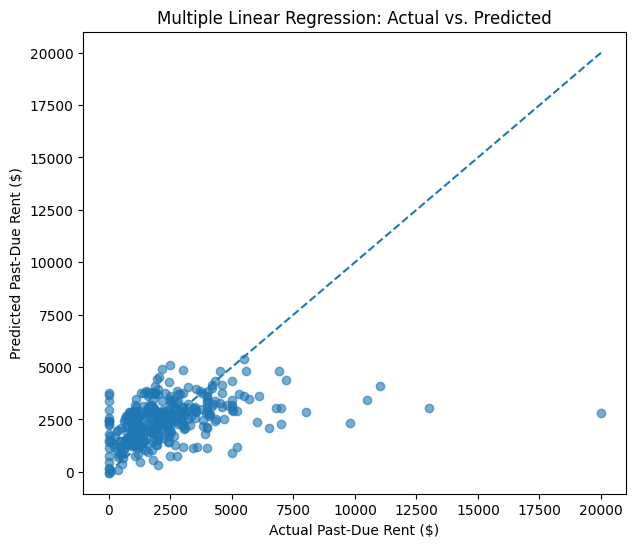

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, linear_predictions, alpha=0.6)

minimum = min(y_test.min(), linear_predictions.min())
maximum = max(y_test.max(), linear_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Actual Past-Due Rent ($)")
plt.ylabel("Predicted Past-Due Rent ($)")
plt.title("Multiple Linear Regression: Actual vs. Predicted")
plt.show()

Based on the graph, the model does a decent job predicting the lower and more common past due rent values, but the predictions become much less accurate as the actual rent owed gets higher. Most of the points are clustered below about
5,000, and many are somewhat close to the perfect prediction line. However, the model clearly underpredicts several of the highest values, including cases around 10,000 to 20,000 in actual past due rent. This shows that the model has some large prediction errors and struggles the most with households that have unusually high rent debt.
**bold text**

### 11. Build a Polynomial Regression model.

Real-world relationships are not always perfectly linear. For this model, use PolynomialFeatures(degree=2, include_bias=False). Apply polynomial transformation to the appropriate numerical variables. Do not automatically apply polynomial expansion to all one-hot encoded categorical variables.

Train the model and calculate RMSE and R².

**Answer:**
- Did Polynomial Regression perform better or worse than Linear Regression?
- What does a degree-2 polynomial allow the model to represent that Linear Regression cannot?
- Why could using a very high polynomial degree lead to overfitting?
- Did making the model more complicated automatically make it better?


In [ ]:
# Create a numerical pipeline that fills missing values, creates degree-2 polynomial features, and scales them.
polynomial_numerical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("polynomial", PolynomialFeatures(degree=2, include_bias=False)),("scaler", StandardScaler())])

# Combine the polynomial numerical pipeline with the same categorical preprocessing used before.
polynomial_preprocessor = ColumnTransformer(transformers=[("num", polynomial_numerical_pipeline, numerical_features),("cat", categorical_pipeline, categorical_features)])

# Create and train a Polynomial Regression pipeline.
polynomial_model = Pipeline(steps=[("preprocessing", polynomial_preprocessor),("model", LinearRegression())])

polynomial_model.fit(X_train, y_train)
polynomial_predictions = polynomial_model.predict(X_test)

# Calculate RMSE and R-squared for Polynomial Regression.
polynomial_rmse = np.sqrt(mean_squared_error(y_test, polynomial_predictions))
polynomial_r2 = r2_score(y_test, polynomial_predictions)

print("Polynomial Regression RMSE:", polynomial_rmse)
print("Polynomial Regression R²:", polynomial_r2)


Polynomial Regression RMSE: 1875.0363526767132
Polynomial Regression R²: 0.14230575540605894


Polynomial Regression performed slightly worse than Linear Regression. Its RMSE was about 1,875, which is a little higher than the Linear Regression RMSE of about 1,861, and its R² was about 0.142, which is lower than the Linear Regression R² of about 0.155. A degree 2 polynomial allows the model to represent curved relationships and interactions between numerical variables that a normal Linear Regression model cannot capture. Using a very high polynomial degree could lead to overfitting because the model may start fitting noise in the training data instead of learning patterns that work well on new data. In this case, making the model more complicated did not automatically make it better.

### 12. Build a Ridge Regression model.

Create a Ridge Regression pipeline using the same training and testing data. Choose a reasonable value for alpha. You may experiment with more than one value.

Calculate RMSE and R².

**Answer:**
- How does Ridge Regression compare with Linear Regression?
- What does regularization do?
- Why can regularization be useful when a model contains many features?


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
# Test several Ridge alpha values using the same training and testing data.
ridge_results = []

for alpha_value in [0.1, 1, 10, 100]:
    ridge_test_model = Pipeline(steps=[("preprocessing", preprocessor),("model", Ridge(alpha=alpha_value))])

    ridge_test_model.fit(X_train, y_train)
    ridge_test_predictions = ridge_test_model.predict(X_test)

    ridge_results.append({"alpha": alpha_value,"RMSE": np.sqrt(mean_squared_error(y_test, ridge_test_predictions)),"R²": r2_score(y_test, ridge_test_predictions)})

display(pd.DataFrame(ridge_results))


,alpha,RMSE,R²
0,0.1,1858.900786,0.157004
1,1.0,1849.175893,0.165801
2,10.0,1840.565962,0.173551
3,100.0,1837.405157,0.176387


In [ ]:
# Use alpha=100 for the final Ridge model because it performed best among the values tested.
ridge_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", Ridge(alpha=100))
])

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_test)

ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression RMSE:", ridge_rmse)
print("Ridge Regression R²:", ridge_r2)


Ridge Regression RMSE: 1837.4051567959143
Ridge Regression R²: 0.17638741634076527


Ridge Regression performed slightly better than Linear Regression. Ridge had an RMSE of about 1,837 and an R² of about 0.176, while Linear Regression had an RMSE of about $1,861 and an R² of about 0.155. Regularization works by shrinking the model’s coefficients so that no single feature has too much influence on the prediction. This can be useful when a model has many features because it can reduce overfitting and help the model perform better on new data.


### 13. Build a Lasso Regression model.

Create a Lasso Regression pipeline using the same training and testing data. Choose a reasonable value for alpha.

Calculate RMSE and R².

**Answer:**
- How does Lasso compare with Linear and Ridge Regression?
- What is an important difference between Ridge and Lasso?
- What can happen to some coefficients when Lasso is used?


In [ ]:
# Test several Lasso alpha values using the same training and testing data.
lasso_results = []

for alpha_value in [1, 5, 10, 20, 50]:
    lasso_test_model = Pipeline(steps=[("preprocessing", preprocessor),("model", Lasso(alpha=alpha_value, max_iter=20000))])

    lasso_test_model.fit(X_train, y_train)
    lasso_test_predictions = lasso_test_model.predict(X_test)

    lasso_results.append({"alpha": alpha_value,"RMSE": np.sqrt(mean_squared_error(y_test, lasso_test_predictions)),"R²": r2_score(y_test, lasso_test_predictions) })

display(pd.DataFrame(lasso_results))


,alpha,RMSE,R²
0,1,1841.893223,0.172359
1,5,1828.986025,0.183918
2,10,1826.443026,0.186186
3,20,1829.881024,0.183119
4,50,1839.013143,0.174945


In [ ]:
# Use alpha=10 for the final Lasso model because it performed best among the values tested.
lasso_model = Pipeline(steps=[("preprocessing", preprocessor),("model", Lasso(alpha=10, max_iter=20000))])

lasso_model.fit(X_train, y_train)
lasso_predictions = lasso_model.predict(X_test)

lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predictions))
lasso_r2 = r2_score(y_test, lasso_predictions)

print("Lasso Regression RMSE:", lasso_rmse)
print("Lasso Regression R²:", lasso_r2)


Lasso Regression RMSE: 1826.4430264030984
Lasso Regression R²: 0.18618559930653933


Lasso Regression performed the best out of the three models. With an alpha of 10, Lasso had an RMSE of about 1,826 and an R² of about 0.186, which is slightly better than Ridge and Linear Regression. One important difference is that Ridge shrinks coefficients toward zero, while Lasso can shrink some coefficients all the way to zero. This means Lasso can basically remove features that are not helping the model very much, which can make the model simpler and sometimes improve its predictions.


### 14. Compare all four models.

Create a DataFrame containing the test-set results for all four models.

| Model | RMSE | R² |
|---|---:|---:|
| Linear Regression | | |
| Polynomial Regression | | |
| Ridge Regression | | |
| Lasso Regression | | |

**Answer:**
- Which model has the lowest RMSE?
- Which model has the highest R²?
- Are the differences between the models large or small?
- Did the most complicated model perform the best?
- Which model would you continue investigating? Explain your choice using evidence from your results.


In [ ]:
# Create a table comparing the test results for all four regression models.
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "RMSE": [
        linear_rmse,
        polynomial_rmse,
        ridge_rmse,
        lasso_rmse
    ],
    "R²": [
        linear_r2,
        polynomial_r2,
        ridge_r2,
        lasso_r2
    ]
})

display(model_results.sort_values("RMSE"))


,Model,RMSE,R²
3,Lasso Regression,1826.443026,0.186186
2,Ridge Regression,1837.405157,0.176387
0,Linear Regression,1861.212827,0.154906
1,Polynomial Regression,1875.036353,0.142306


Lasso Regression had the lowest RMSE at about $1,826 and the highest R² at about 0.186, so it performed the best out of the four models. The differences between the models are fairly small, but Ridge and Lasso both performed a little better than the basic Linear Regression model. Polynomial Regression was the most complicated model, but it actually performed the worst, with the highest RMSE and lowest R². This shows that making the model more complicated did not automatically make it better. I would continue investigating Lasso Regression because it gave the best results on the testing data and had the strongest combination of the lowest prediction error and highest R².

### 15. Test your selected model on two hypothetical households.

Create TWO new hypothetical cases. Do not copy an actual person from the dataset.

Change several characteristics between the two cases, such as:
- household size
- monthly household income
- employment status
- housing voucher status
- utility situation
- monthly rent

Use your selected pipeline to predict `past_due_rent` for both cases.

Then explain:
- How are the two households different?
- How different are the predictions?
- Does the difference seem reasonable based on the information you provided?


In [ ]:
# Create two fictional households with different income, employment, housing, and utility situations.
hypothetical_households = pd.DataFrame([
    {
        "adults_in_household": 1,
        "children_in_household": 0,
        "household_has_65plus": "No",
        "monthly_household_income": 3200,
        "income_sources": "Full-time employment",
        "employment_status": "Employed",
        "has_housing_voucher": "No",
        "eviction_in_progress": "I don't know",
        "behind_on_utilities": "No",
        "main_reason_behind_on_rent": "Unexpected expense",
        "intake_quarter": "2026-Q3",
        "monthly_rent": 1100
    },
    {
        "adults_in_household": 2,
        "children_in_household": 3,
        "household_has_65plus": "No",
        "monthly_household_income": 900,
        "income_sources": "Food benefits - TANF/SNAP",
        "employment_status": "Unemployed but want to find work",
        "has_housing_voucher": "Yes",
        "eviction_in_progress": "Yes",
        "behind_on_utilities": "Yes",
        "main_reason_behind_on_rent": "Lost a job/had hours cut",
        "intake_quarter": "2026-Q3",
        "monthly_rent": 1650
    }
])

# Use the selected Lasso pipeline to predict past-due rent for both fictional households.
hypothetical_predictions = lasso_model.predict(hypothetical_households)

prediction_results = hypothetical_households.copy()
prediction_results["predicted_past_due_rent"] = hypothetical_predictions

display(prediction_results)
print("Household 1 predicted past-due rent:", round(hypothetical_predictions[0], 2))
print("Household 2 predicted past-due rent:", round(hypothetical_predictions[1], 2))
print("Difference:", round(hypothetical_predictions[1] - hypothetical_predictions[0], 2))


,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,predicted_past_due_rent
0,1,0,No,3200,Full-time employment,Employed,No,I don't know,No,Unexpected expense,2026-Q3,1100,1944.796154
1,2,3,No,900,Food benefits - TANF/SNAP,Unemployed but want to find work,Yes,Yes,Yes,Lost a job/had hours cut,2026-Q3,1650,3273.777197


Household 1 predicted past-due rent: 1944.8
Household 2 predicted past-due rent: 3273.78
Difference: 1328.98


The first household has one adult, no children, a monthly income of about 3,200, full-time employment, no housing voucher, and 1,100 in monthly rent. The second household has two adults and three children, only 900 in monthly income, is unemployed, has a housing voucher, is behind on utilities, has an eviction in progress, and pays 1,650 in rent. The model predicted about 1,945 in past due rent for the first household and about 3,274 for the second, which is a difference of about 1,329. That difference seems reasonable because the second household has a lower income, higher rent, and more signs of financial difficulty. However, this is still only a prediction based on patterns in the data, not proof that those factors directly caused the higher amount of past due rent.

## Part 4 – Interpret the Results

### 16. What did your models tell you?

Write a short interpretation of your overall results. Address:
- Which model performed best on the test data?
- Approximately how large are the model's typical prediction errors?
- Did Polynomial Regression provide a meaningful improvement?
- Did regularization improve the results?
- What does your model appear able to predict reasonably well?
- Where does it appear to struggle?

Use evidence from your RMSE, R², visualizations, and predictions.


Lasso Regression performed the best, with an RMSE of about 1,826 and an R² of about 0.186. Polynomial Regression did not improve the results, while Ridge and Lasso both did slightly better than Linear Regression. The models seem to predict the more common rent amounts better, but they struggle with very high past due rent and tend to underpredict those cases. Overall, the models found some useful patterns, but there is still a lot of variation they cannot explain.


### 17. What is your overall finding for SLCM?

In 5–8 sentences, explain your analysis as if you were speaking to someone from SLCM who has not taken a machine-learning course.

Your explanation should address:
- What were you trying to predict?
- What information did you use?
- How successful was the model?
- What is the most important finding?
- Could this type of model potentially be useful for understanding community needs?
- What is one important limitation?

Do not claim that an input variable causes someone to have more or less past-due rent simply because the model found a relationship.


I was trying to predict how much past due rent a household might have using information like income, employment, household size, rent, utilities, and housing situation. The best model was Lasso Regression, but it was still usually off by about 1,826. The biggest finding was that more complicated models did not always perform better, since Polynomial Regression was actually worse. Ridge and Lasso improved the results a little, which shows regularization helped. This type of model could still be useful for finding general patterns in community needs and showing what information may matter most. However, it is not accurate enough to predict every household well, especially households with very high past due rent. It also only shows relationships in the data and does not prove that any one factor causes someone to owe more rent.